In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn import tree

from IPython.display import Image

In [42]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target

X = iris.data
y = iris.target
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [8]:
model = DecisionTreeClassifier(criterion="entropy",max_depth=5, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)


Confusion Matrix:


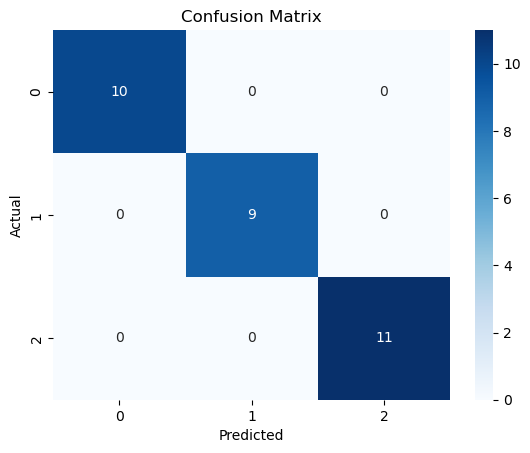

In [9]:
y_pred = model.predict(X_test)

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

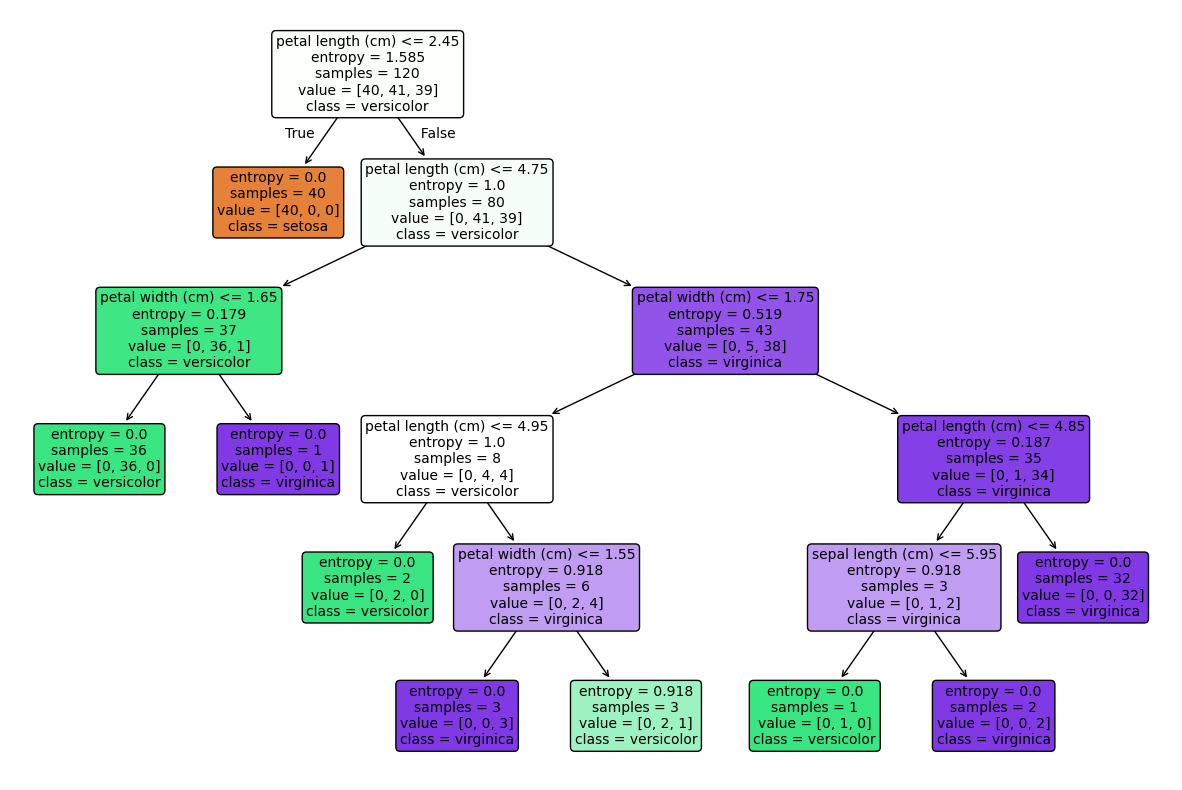

In [10]:
plt.figure(figsize=(15,10))
tree.plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

In [11]:
model = DecisionTreeClassifier(criterion="entropy",max_depth=3, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

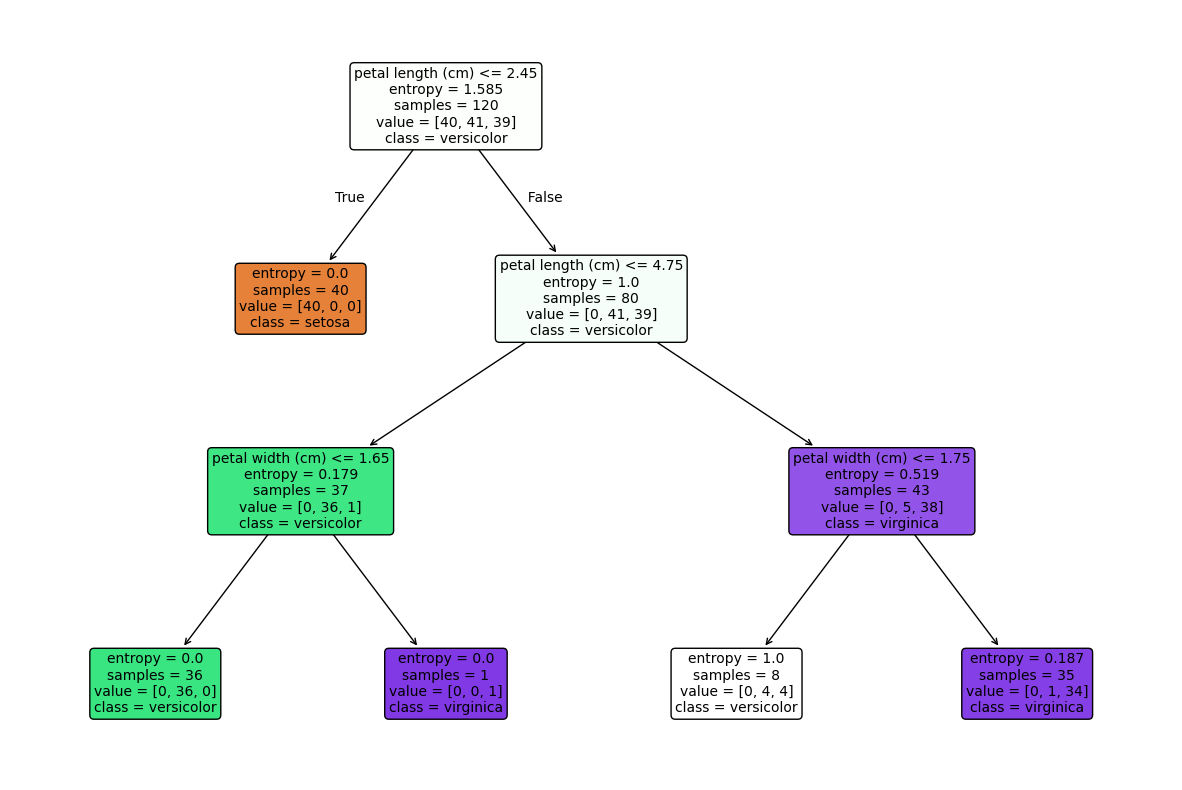

In [12]:
plt.figure(figsize=(15,10))
tree.plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

In [13]:
model = DecisionTreeClassifier(criterion="entropy",min_samples_split=10, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

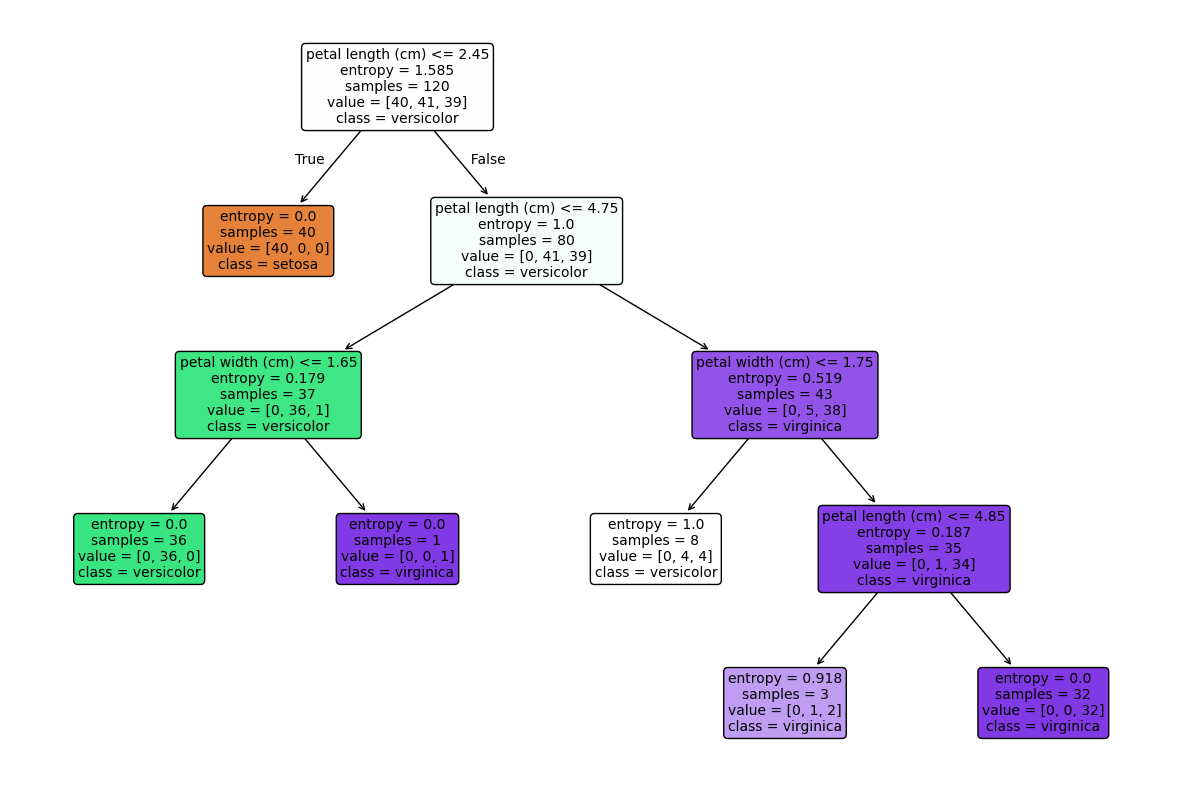

In [14]:
plt.figure(figsize=(15,10))
tree.plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

In [23]:
model = DecisionTreeClassifier(criterion="entropy",min_samples_leaf=2, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

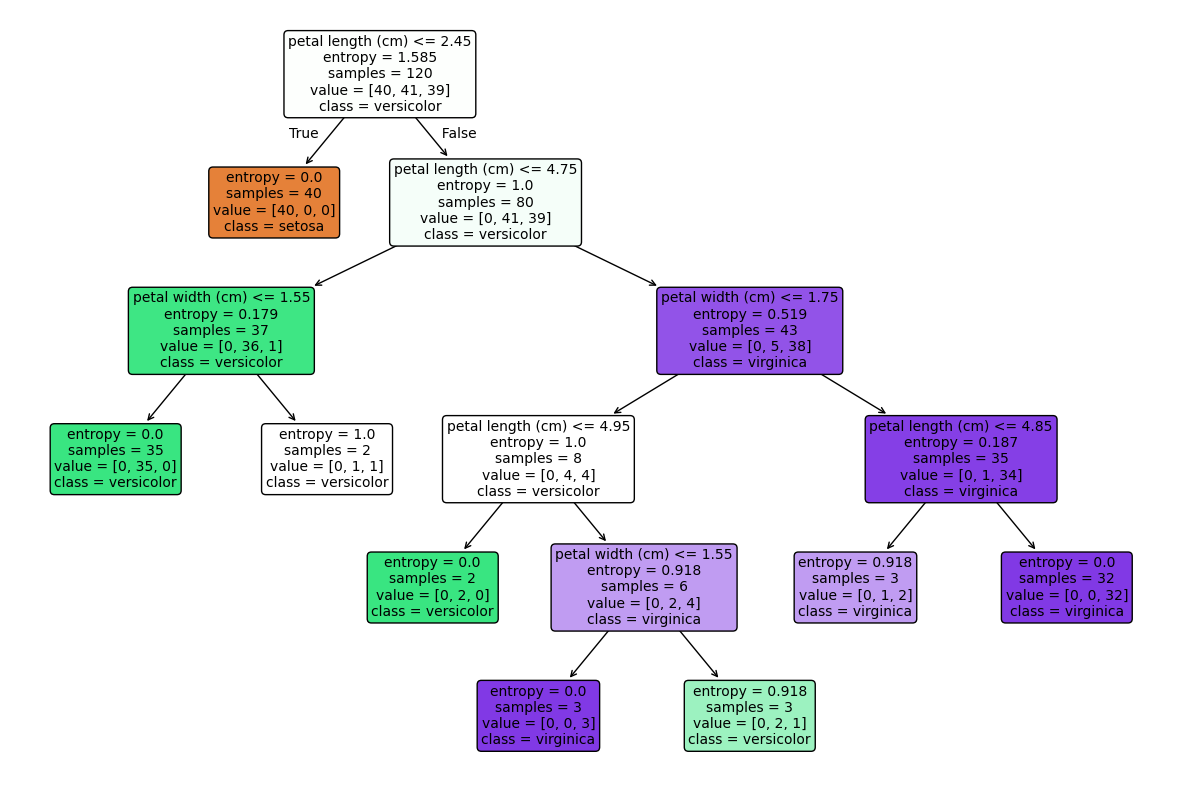

In [24]:
plt.figure(figsize=(15,10))
tree.plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

# HR

In [25]:
hr=pd.read_csv("D:\Machine Learning\Datasets\HR_comma_sep.csv")
hr

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14990,0.40,0.57,2,151,3,0,1,0,support,low
14991,0.37,0.48,2,160,3,0,1,0,support,low
14992,0.37,0.53,2,143,3,0,1,0,support,low
14993,0.11,0.96,6,280,4,0,1,0,support,low


In [ ]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder


X , y = hr.drop('left',axis=1) , hr['left']
ohe = OneHotEncoder(drop='first', sparse_output=False).set_output(transform="pandas")
col_transformer = ColumnTransformer([("OHE", ohe, make_column_selector(dtype_include=object))], 
                                    remainder='passthrough', 
                                    verbose_feature_names_out=False)
col_transformer = col_transformer.set_output(transform="pandas")
X = col_transformer.fit_transform(X)


In [27]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.3,random_state=25,stratify=y)

In [28]:
dtc=DecisionTreeClassifier(random_state=42)
dtc.fit(X_train,y_train)
y_pred=dtc.predict(X_test)

In [34]:
from sklearn.metrics import recall_score,precision_score
print('precision_score: ')
precision_score(y_test,y_pred,pos_label=1)


precision_score: 


0.9455535390199638

# Finding Best combition of decision tree classifier

In [40]:
from tqdm import tqdm

#  hyperparameter search
depths=[None,3,4,5,6,7,8]
min_samples=[2,10,50,100,250]
min_leaf=[1,10,50,100,250]
scores=[]
for d in tqdm(depths):
    for s in min_samples:
        for l in min_leaf:
            dtc=DecisionTreeClassifier(max_depth=d,min_samples_leaf=l,min_samples_split=s,random_state=42)
            dtc.fit(X_train,y_train)
            y_pred=dtc.predict(X_test)
            scores.append([d,s,l,precision_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=('Depth','Min_Samples','Min_Leaf','precision_score'))
df_scores.sort_values('precision_score',ascending=False)

100%|██████████| 7/7 [00:03<00:00,  2.28it/s]


,Depth,Min_Samples,Min_Leaf,precision_score
15,NaN,100,1,0.990070
20,NaN,250,1,0.990040
10,NaN,50,1,0.989098
160,8.0,50,1,0.988119
165,8.0,100,1,0.988107
...,...,...,...,...
29,3.0,2,250,0.862457
44,3.0,100,250,0.862457
39,3.0,50,250,0.862457
34,3.0,10,250,0.862457


In [49]:
best_params = df_scores.sort_values('precision_score', ascending=False).iloc[0]
print("=" * 60)
print("BEST DECISION TREE PARAMETERS")
print("=" * 60)
print(f"Max Depth: {best_params['Depth']}")
print(f"Min Samples Split: {int(best_params['Min_Samples'])}")
print(f"Min Samples Leaf: {int(best_params['Min_Leaf'])}")
print(f"Precision Score: {best_params['precision_score']:.4f}")
print("=" * 60)


BEST DECISION TREE PARAMETERS
Max Depth: nan
Min Samples Split: 100
Min Samples Leaf: 1
Precision Score: 0.9901


Visulaizing the best results


Top 10 Parameter Combinations:
     Depth  Min_Samples  Min_Leaf  precision_score
15     NaN          100         1         0.990070
20     NaN          250         1         0.990040
10     NaN           50         1         0.989098
160    8.0           50         1         0.988119
165    8.0          100         1         0.988107
170    8.0          250         1         0.988072
135    7.0           50         1         0.986180
140    7.0          100         1         0.986166
145    7.0          250         1         0.986125
141    7.0          100        10         0.985060


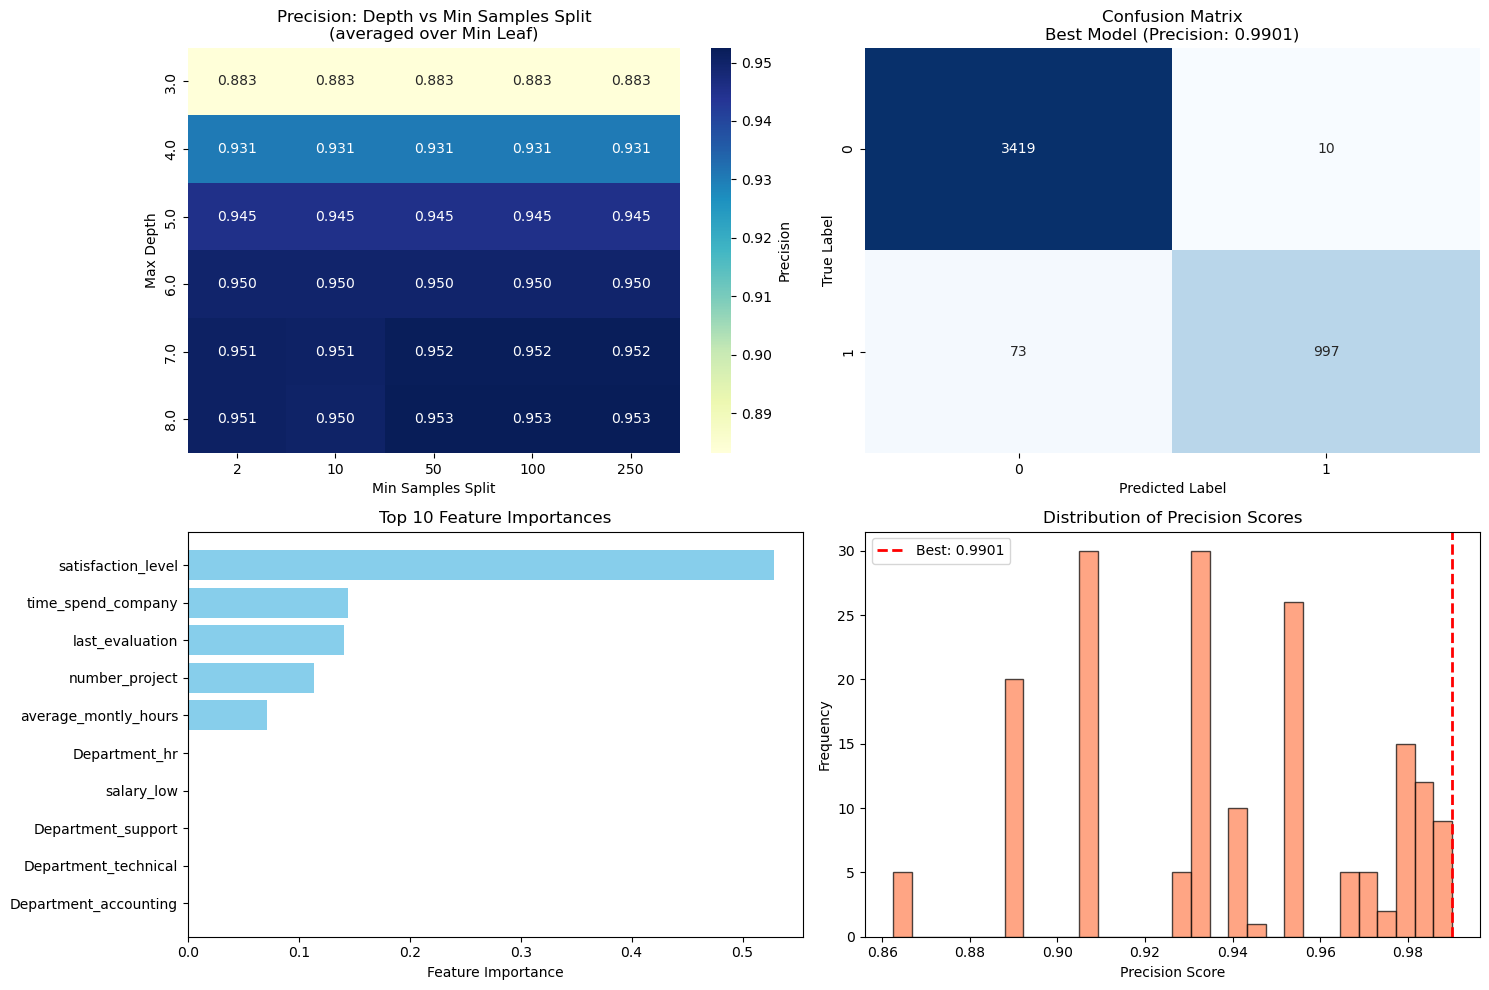


CLASSIFICATION REPORT - BEST MODEL
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3429
           1       0.99      0.93      0.96      1070

    accuracy                           0.98      4499
   macro avg       0.98      0.96      0.97      4499
weighted avg       0.98      0.98      0.98      4499


Tree too deep for visualization (depth > 5)
Consider using a smaller max_depth for visualization purposes


In [53]:
max_depth_val = None if pd.isna(best_params['Depth']) else int(best_params['Depth'])

# Train the best model
best_dtc = DecisionTreeClassifier(
    max_depth=max_depth_val,
    min_samples_split=int(best_params['Min_Samples']),
    min_samples_leaf=int(best_params['Min_Leaf']),
    random_state=42
)
best_dtc.fit(X_train, y_train)
y_pred_best = best_dtc.predict(X_test)

# Visualization 1: Top 10 parameter combinations
print("\nTop 10 Parameter Combinations:")
print(df_scores.sort_values('precision_score', ascending=False).head(10))

# Visualization 2: Heatmap of depth vs min_samples (averaged over min_leaf)
plt.figure(figsize=(15, 10))

# Plot 1: Heatmap
plt.subplot(2, 2, 1)
pivot_depth_samples = df_scores.groupby(['Depth', 'Min_Samples'])['precision_score'].mean().reset_index()
pivot_table = pivot_depth_samples.pivot(index='Depth', columns='Min_Samples', values='precision_score')
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='YlGnBu', cbar_kws={'label': 'Precision'})
plt.title('Precision: Depth vs Min Samples Split\n(averaged over Min Leaf)')
plt.xlabel('Min Samples Split')
plt.ylabel('Max Depth')

# Plot 2: Confusion Matrix
plt.subplot(2, 2, 2)
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix\nBest Model (Precision: {best_params["precision_score"]:.4f})')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Plot 3: Feature Importance
plt.subplot(2, 2, 3)
if hasattr(X_train, 'columns'):
    feature_names = X_train.columns
else:
    feature_names = [f'Feature {i}' for i in range(X_train.shape[1])]

importances = best_dtc.feature_importances_
indices = importances.argsort()[-10:][::-1]  # Top 10 features

plt.barh(range(len(indices)), importances[indices], color='skyblue')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Feature Importance')
plt.title('Top 10 Feature Importances')
plt.gca().invert_yaxis()

# Plot 4: Precision distribution
plt.subplot(2, 2, 4)
plt.hist(df_scores['precision_score'], bins=30, color='coral', edgecolor='black', alpha=0.7)
plt.axvline(best_params['precision_score'], color='red', linestyle='--', linewidth=2, 
            label=f'Best: {best_params["precision_score"]:.4f}')
plt.xlabel('Precision Score')
plt.ylabel('Frequency')
plt.title('Distribution of Precision Scores')
plt.legend()

plt.tight_layout()
plt.show()

# Classification Report
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT - BEST MODEL")
print("=" * 60)
print(classification_report(y_test, y_pred_best))

# Optional: Visualize the actual tree (use carefully if tree is large)
if best_params['Depth'] is not None and best_params['Depth'] <= 5:
    plt.figure(figsize=(20, 10))
    plot_tree(best_dtc, 
              feature_names=feature_names,
              class_names=[str(c) for c in best_dtc.classes_],
              filled=True, 
              rounded=True,
              fontsize=10)
    plt.title('Best Decision Tree Visualization')
    plt.tight_layout()
    plt.show()
else:
    print("\nTree too deep for visualization (depth > 5)")
    print("Consider using a smaller max_depth for visualization purposes")

Examining the best tree

In [63]:
best_tree = DecisionTreeClassifier(random_state=25, max_depth=None, min_samples_split=0.01, min_samples_leaf=1)
best_tree.fit(X, y)
df_imp = pd.DataFrame({"feature": X.columns, "importance": best_tree.feature_importances_})
df_imp = df_imp.sort_values("importance").head(10)

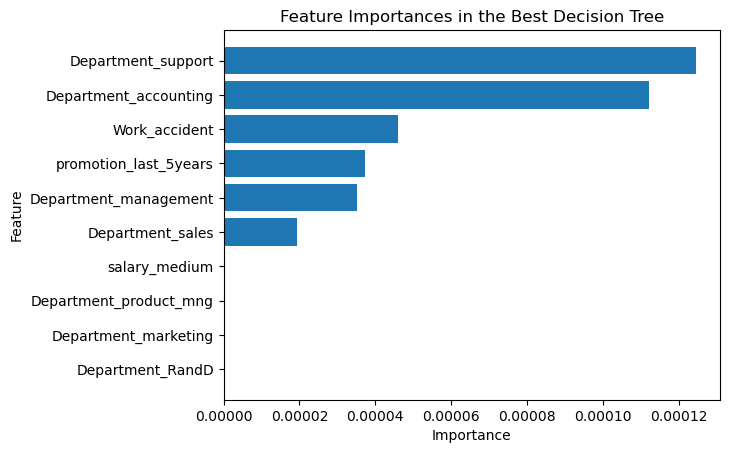

In [64]:
import matplotlib.pyplot as plt
plt.barh(df_imp["feature"], df_imp["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importances in the Best Decision Tree")
plt.show()